# Homework 2: Verifier Reliability, Calibration, and Distillation Under Weak Supervision

## Assignment Overview

This assignment investigates verifier quality and weak supervision for math reasoning (GSM8K).
We implement six diverse verifiers (outcome and process-style), develop ensemble methods without labels, design a lightweight process verifier, and distill the ensemble into a compact model.

### Key Components:
- **Part A**: Verifier Zoo (6 diverse verifiers)
- **Part B**: Weaver-lite Weighting Without Labels  
- **Part C**: Process Supervision Without Humans (First-Error Localization)
- **Part D**: Ensemble Distillation
- **Evaluation**: Diagnostics, Calibration, and Robustness

---

In [ ]:
# If needed:
!pip -q install datasets pandas transformers accelerate scikit-learn matplotlib

from datasets import load_dataset
import pandas as pd
import numpy as np

import torch, gc
torch.set_grad_enabled(False)

from hw2_helpers import (
    build_fixed_candidate_pool_records,
    compute_global_stats_from_pool,
    dawid_skene_em,
    extract_candidate_answer,
    extract_true_answer,
    final_re,
    fit_agreement_temperature,
    load_judge_model,
    loo_agreement_weights,
    load_jsonl_records,
    make_demo_candidates_from_gold,
    make_deceptive_wrong,
    normalize_scores,
    pairwise_verifier_correlations,
    pseudo_first_error_index,
    save_jsonl_records,
    score_candidates_raw,
    set_judge_components,
    show_example,
    split_into_steps,
    split_by_problem_id,
    step_feature_map,
    verifier_exact_match,
    verifier_format_confidence,
    verifier_numeric_distance,
    verifier_step_consistency,
    verifier_step_plausibility_judge,
    verifier_step_to_outcome_coherence,
    votes_from_scores_threshold,
    votes_from_scores_topk,
    weighted_candidate_scores,
)

import time
notebook_start_time = time.time()


## Load GSM8K Dataset
Use the GSM8K dataset from Hugging Face for math-reasoning evaluation.


In [ ]:
dataset = load_dataset("gsm8k", "main")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

main/train-00000-of-00001.parquet:   0%|          | 0.00/2.31M [00:00<?, ?B/s]

main/test-00000-of-00001.parquet:   0%|          | 0.00/419k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/7473 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1319 [00:00<?, ? examples/s]

Inspect a few training examples to confirm the question/answer format, including the `####` final-answer convention.


In [ ]:
for i in range(3):
    show_example(dataset["train"][i])



QUESTION:
 Natalia sold clips to 48 of her friends in April, and then she sold half as many clips in May. How many clips did Natalia sell altogether in April and May?

SOLUTION:
 Natalia sold 48/2 = <<48/2=24>>24 clips in May.
Natalia sold 48+24 = <<48+24=72>>72 clips altogether in April and May.
#### 72

QUESTION:
 Weng earns $12 an hour for babysitting. Yesterday, she just did 50 minutes of babysitting. How much did she earn?

SOLUTION:
 Weng earns 12/60 = $<<12/60=0.2>>0.2 per minute.
Working 50 minutes, she earned 0.2 x 50 = $<<0.2*50=10>>10.
#### 10

QUESTION:
 Betty is saving money for a new wallet which costs $100. Betty has only half of the money she needs. Her parents decided to give her $15 for that purpose, and her grandparents twice as much as her parents. How much more money does Betty need to buy the wallet?

SOLUTION:
 In the beginning, Betty has only 100 / 2 = $<<100/2=50>>50.
Betty's grandparents gave her 15 * 2 = $<<15*2=30>>30.
This means, Betty needs 100 - 50 - 30 

Convert the dataset to pandas DataFrames for quick structural inspection.


In [ ]:
train_df = pd.DataFrame(dataset["train"])
test_df = pd.DataFrame(dataset["test"])
print("GSM8K train size:", len(train_df))
print("GSM8K test size:", len(test_df))
# Show the first five rows
train_df.head()

GSM8K train size: 7473
GSM8K test size: 1319


,question,answer
0,Natalia sold clips to 48 of her friends in Apr...,Natalia sold 48/2 = <<48/2=24>>24 clips in May...
1,Weng earns $12 an hour for babysitting. Yester...,Weng earns 12/60 = $<<12/60=0.2>>0.2 per minut...
2,Betty is saving money for a new wallet which c...,"In the beginning, Betty has only 100 / 2 = $<<..."
3,"Julie is reading a 120-page book. Yesterday, s...",Maila read 12 x 2 = <<12*2=24>>24 pages today....
4,James writes a 3-page letter to 2 different fr...,He writes each friend 3*2=<<3*2=6>>6 pages a w...


## Answer Pattern and Regex

GSM8K solutions end with a standardized final-answer line:

- Final numeric answer appears after `####`
- It is on its own line
- It may be an integer or decimal

Because this format is consistent, we can reliably extract the true answer with a regular expression.


In [ ]:
# Regex is defined in hw2_helpers.py
print("Final answer regex:", final_re.pattern)


Final answer regex: ####\s*([-+]?\d+(?:\.\d+)?)


Use `extract_true_answer` to parse each full solution and keep only the numeric value after `####`.


In [ ]:
dataset = dataset.map(lambda x: {"true_answer": extract_true_answer(x)})


Map:   0%|          | 0/7473 [00:00<?, ? examples/s]

Map:   0%|          | 0/1319 [00:00<?, ? examples/s]

Verify that the extracted `true_answer` aligns with the original `answer` text.


In [ ]:
for i in range(3):
    show_example(dataset["train"][i])



QUESTION:
 Natalia sold clips to 48 of her friends in April, and then she sold half as many clips in May. How many clips did Natalia sell altogether in April and May?

SOLUTION:
 Natalia sold 48/2 = <<48/2=24>>24 clips in May.
Natalia sold 48+24 = <<48+24=72>>72 clips altogether in April and May.
#### 72

TRUE ANSWER: 72

QUESTION:
 Weng earns $12 an hour for babysitting. Yesterday, she just did 50 minutes of babysitting. How much did she earn?

SOLUTION:
 Weng earns 12/60 = $<<12/60=0.2>>0.2 per minute.
Working 50 minutes, she earned 0.2 x 50 = $<<0.2*50=10>>10.
#### 10

TRUE ANSWER: 10

QUESTION:
 Betty is saving money for a new wallet which costs $100. Betty has only half of the money she needs. Her parents decided to give her $15 for that purpose, and her grandparents twice as much as her parents. How much more money does Betty need to buy the wallet?

SOLUTION:
 In the beginning, Betty has only 100 / 2 = $<<100/2=50>>50.
Betty's grandparents gave her 15 * 2 = $<<15*2=30>>30.
This

## Held-Out Evaluation Split

Use a fixed subset of 200 GSM8K test problems for faster, reproducible evaluation.


In [ ]:
# We'll take examples from the TEST split (these are held-out from training).
test_split = dataset["test"]
print("Total test examples:", len(test_split))

Total test examples: 1319


Shuffle and select 200 test examples with a fixed seed so others can reproduce the exact same subset.


In [ ]:
heldout_200_shuffled = test_split.shuffle(seed=42).select(range(200))
print("Held-out subset size (random 200, seed=42):", len(heldout_200_shuffled))

# We'll use the shuffled one going forward (more representative than "first 200")
heldout = heldout_200_shuffled

example = heldout[0]
show_example(example)

Held-out subset size (random 200, seed=42): 200

QUESTION:
 Darrell and Allen's ages are in the ratio of 7:11. If their total age now is 162, calculate Allen's age 10 years from now.

SOLUTION:
 The total ratio representing their ages is 7+11= <<7+11=18>>18
Since the fraction of the ratio that represents Allen's age is 11/18, Allen's current age is 11/18*162 = <<11/18*162=99>>99
If Allen is currently 99 years old, in 10 years he will be 99+10 = <<99+10=109>>109 years old
#### 109

TRUE ANSWER: 109


### Freeze Fixed Candidate Pool (JSONL)

For each held-out problem, build a **static pool of K candidates once** and store it. All verifier methods below reuse this exact frozen pool.

Generate candidates once → freeze them → study verification.

Key difference from your HW: you will work on a fixed candidate set (pre-generated solutions) and optimize verification, not test-time sampling policies.


In [ ]:
# Build and freeze a fixed candidate pool per problem.
K_CANDIDATES = 8
pool_path = f"gsm8k_200_fixed_pool_k{K_CANDIDATES}.jsonl"

pool_records = build_fixed_candidate_pool_records(
    heldout,
    k=K_CANDIDATES,
    max_examples=len(heldout),
    seed=42,
)
save_jsonl_records(pool_records, pool_path)

print("Saved fixed candidate pool to:", pool_path)
print("Num problems:", len(pool_records))
print("Candidates per problem (first):", len(pool_records[0]["candidates"]))


Saved fixed candidate pool to: gsm8k_200_fixed_pool_k8.jsonl
Num problems: 200
Candidates per problem (first): 8


Read the frozen pool JSONL and inspect one record.


In [ ]:
frozen_pool = load_jsonl_records(pool_path)

print("Loaded frozen pool records:", len(frozen_pool))
print("\n=== Frozen Pool Record 0 ===")
print("id:", frozen_pool[0]["id"])
print("question:", frozen_pool[0]["question"][:120], "...")
print("true_answer:", frozen_pool[0]["true_answer"])
print("num candidates:", len(frozen_pool[0]["candidates"]))
print("candidate[0] keys:", list(frozen_pool[0]["candidates"][0].keys()))
print("candidate[0] text snippet:", frozen_pool[0]["candidates"][0]["text"][:160], "...")


Loaded frozen pool records: 200

=== Frozen Pool Record 0 ===
id: gsm8k_0
question: Darrell and Allen's ages are in the ratio of 7:11. If their total age now is 162, calculate Allen's age 10 years from no ...
true_answer: 109
num candidates: 8
candidate[0] keys: ['text', 'final', 'steps', 'question_hint']
candidate[0] text snippet: The total ratio representing their ages is 7+11= <<7+11=18>>18
Since the fraction of the ratio that represents Allen's age is 11/18, Allen's current age is 11/1 ...


### Pool Integrity Check: Candidate `steps` Coverage

Before downstream training/evaluation, verify candidate step fields are present.
If any candidate is missing `steps`, we backfill by splitting candidate text on the fly.


In [ ]:
# Pool integrity check: candidate `steps` coverage and fallback backfill.

def ensure_steps_exist(records, name="records"):
    total = 0
    missing_steps_key = 0
    empty_steps = 0

    for rec in records:
        for cand in rec["candidates"]:
            total += 1
            if "steps" not in cand or cand["steps"] is None:
                missing_steps_key += 1
                cand["steps"] = split_into_steps(cand.get("text", ""))
            if len(cand.get("steps", [])) == 0:
                empty_steps += 1

    print(f"{name}: total candidates={total}")
    print(f"{name}: missing `steps` backfilled={missing_steps_key}")
    print(f"{name}: empty `steps` after backfill={empty_steps} ({empty_steps/max(total,1):.1%})")


print("\n=== Pool integrity check: candidate `steps` coverage ===")
ensure_steps_exist(pool_records, name="pool_records")
ensure_steps_exist(frozen_pool, name="frozen_pool")



=== Pool integrity check: candidate `steps` coverage ===
pool_records: total candidates=1565
pool_records: missing `steps` backfilled=0
pool_records: empty `steps` after backfill=0 (0.0%)
frozen_pool: total candidates=1565
frozen_pool: missing `steps` backfilled=0
frozen_pool: empty `steps` after backfill=0 (0.0%)


## Part A: Verifier Zoo (6 Diverse Verifiers)

Homework 1 improved quality by generating more candidates, but that is computationally expensive.
Here we use **verifiers** to score candidate answers instead.

### Verifier Classification
- **Outcome-style verifiers**: Score only the final answer
- **Process-style verifiers**: Score the full solution including reasoning

### Outcome-Style Verifiers
Outcome-style verifiers score only the final answer, not the reasoning process.


### Exact-Match Verifier


Sanity check: score the correct solution and a clearly wrong candidate to confirm exact-match behavior.


In [ ]:
# -----------------------------
# Simple Sanity Check
# -----------------------------
# Correct answer should return 1.0
print("Gold Answer Score:", verifier_exact_match(example["answer"], example["true_answer"]))

# Fake incorrect answer should return 0.0
print("Fake Wrong Answer Score:", verifier_exact_match("Some reasoning... #### 999",example["true_answer"]))


Gold Answer Score: 1.0
Fake Wrong Answer Score: 0.0


### Numeric Distance Verifier
Numeric distance gives a smooth score in `[0, 1]` based on closeness to the true answer.
Exact match is `1.0`; larger errors trend toward `0.0`; missing/invalid answers score `0.0`.


In [ ]:
example = heldout[0]
true_a = example["true_answer"]

print("True answer:", true_a)

candidates = [
    ("Exact", f"Reasoning... #### {true_a}"),
    ("Off by 1", f"Reasoning... #### {true_a + 1}"),
    ("Off by 2", f"Reasoning... #### {true_a + 2}"),
    ("Far", f"Reasoning... #### {true_a + 100}"),
    ("Missing", "Reasoning without final marker")
]

for label, cand in candidates:
    print(f"\n{label}")
    print("  Numeric Distance:", verifier_numeric_distance(cand, true_a))
    print("  Exact Match:", verifier_exact_match(cand, true_a))

True answer: 109

Exact
  Numeric Distance: 1.0
  Exact Match: 1.0

Off by 1
  Numeric Distance: 0.5
  Exact Match: 0.0

Off by 2
  Numeric Distance: 0.3333333333333333
  Exact Match: 0.0

Far
  Numeric Distance: 0.009900990099009901
  Exact Match: 0.0

Missing
  Numeric Distance: 0.0
  Exact Match: 0.0


### Format Confidence Verifier
Penalize missing or ambiguous final-answer formatting.


In [ ]:
# -----------------------------
# Sanity Check: Format Confidence
# -----------------------------
example = heldout[0]
true_a = example["true_answer"]

print("\n=== Format Confidence Sanity Check ===")
print("True answer:", true_a)

test_candidates = [
    ("Correct GSM8K answer format (from dataset solution)", example["answer"]),
    ("Good final answer at end", f"Some reasoning...\nTherefore the answer is:\n#### {true_a}"),
    ("Missing final marker", "Some reasoning... I think it's 12 but I won't format it."),
    ("Ambiguous: two finals", f"Reasoning...\n#### {true_a}\nMore reasoning...\n#### {true_a + 1}"),
    ("Final appears early (not at end)", f"#### {true_a}\nSome more reasoning after the final answer."),
]

for label, cand_text in test_candidates:
    score = verifier_format_confidence(cand_text)
    parsed = extract_candidate_answer(cand_text)  # reuse your existing helper
    print(f"\n{label}")
    print("  Extracted final:", parsed)
    print("  Format confidence score:", score)


=== Format Confidence Sanity Check ===
True answer: 109

Correct GSM8K answer format (from dataset solution)
  Extracted final: 109
  Format confidence score: 1.0

Good final answer at end
  Extracted final: 109
  Format confidence score: 1.0

Missing final marker
  Extracted final: None
  Format confidence score: 0.0

Ambiguous: two finals
  Extracted final: 109
  Format confidence score: 0.4

Final appears early (not at end)
  Extracted final: 109
  Format confidence score: 1.0


### Process-Style Verifiers
Process-style verifiers score the full solution, including intermediate reasoning.
For this assignment, we use three process verifiers:

- **Step consistency heuristic**: flags contradictions, impossible counts, division by zero, etc.
- **Step plausibility judge (small LLM)**: asks whether each step is valid given prior steps.
- **Step-to-outcome coherence**: checks whether intermediate numbers support the final answer.


## Process Verifier 1: Step Consistency Heuristic

This verifier looks for obvious internal inconsistencies, for example:

- Division by zero
- Impossible negative quantities (for counting contexts)
- Explicit arithmetic contradictions (for example, `12 = 5 + 6`)

It does not use the true answer; it only checks whether the reasoning is internally coherent.


Run a quick sanity check on:
- A real dataset solution
- A candidate with bad arithmetic
- A candidate with division by zero
- A candidate with impossible negative counts


In [ ]:
# -----------------------------
# Sanity Check: Step Consistency
# -----------------------------
example = heldout[0]

print("\n=== Step Consistency Sanity Check ===")

# 1) Real dataset solution (should usually score relatively high)
score_real = verifier_step_consistency(example["answer"])
print("\nDataset solution score:", score_real)

# 2) Explicit arithmetic contradiction
bad_arith = "We compute: 12 = 5 + 6\nSo the answer is #### 12"
print("\nBad arithmetic score (expect low):", verifier_step_consistency(bad_arith))

# 3) Division by zero
div0 = "We divide 10 by 0: 10 / 0\nSo the answer is #### 0"
print("\nDivision by zero score (expect 0.0):", verifier_step_consistency(div0))

# 4) Negative counts (impossible units)
neg_units = "We end up with -3 apples after giving away 5.\nSo the answer is #### -3"
print("\nNegative count score (expect penalty):", verifier_step_consistency(neg_units))


=== Step Consistency Sanity Check ===

Dataset solution score: 1.0

Bad arithmetic score (expect low): 0.0

Division by zero score (expect 0.0): 0.0

Negative count score (expect penalty): 1.0


## Process Verifier 2: Step Plausibility Judge (Small LLM)

This verifier uses a small instruction-tuned model as a step judge.

For each candidate:
1. Split the solution into steps.
2. Ask whether each step is valid given the question and previous steps.
3. Convert each judgment to a score in `[0, 1]`.
4. Average step scores into one candidate-level score.

This is a weak but useful signal that can catch subtle reasoning errors.


In [ ]:
# -----------------------------
# Load a small LLM "judge" model
# -----------------------------
JUDGE_MODEL_NAME = "Qwen/Qwen2.5-1.5B-Instruct"
judge_tokenizer, judge_model = None, None

try:
    judge_tokenizer, judge_model = load_judge_model(JUDGE_MODEL_NAME)
    set_judge_components(judge_tokenizer, judge_model)
    print("Judge model loaded:", JUDGE_MODEL_NAME)
except Exception as e:
    print("Judge model load failed. Continuing with heuristic-only mode.")
    print("Reason:", type(e).__name__, str(e)[:200])


config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors:   0%|          | 0.00/3.09G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Judge model loaded: Qwen/Qwen2.5-1.5B-Instruct


In [ ]:
# -----------------------------
# Sanity Check: Step plausibility judge
# -----------------------------
ex = heldout[0]
q = ex["question"]

good_candidate = "We add 3 and 4 to get 7.\nSo the answer is #### 7"
bad_candidate = "We divide 10 by 0 to get infinity.\nSo the answer is #### 5"

print("\n=== Step Plausibility Judge Sanity Check ===")
print("Good candidate score:", verifier_step_plausibility_judge(good_candidate, q))
print("Bad candidate score:", verifier_step_plausibility_judge(bad_candidate, q))

print("\n(Reference) Step consistency heuristic:")
print("Good candidate consistency:", verifier_step_consistency(good_candidate))
print("Bad candidate consistency:", verifier_step_consistency(bad_candidate))

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



=== Step Plausibility Judge Sanity Check ===
Good candidate score: 0.0
Bad candidate score: 0.0

(Reference) Step consistency heuristic:
Good candidate consistency: 1.0
Bad candidate consistency: 1.0


## Process Verifier 3: Step-to-Outcome Coherence

This verifier checks whether intermediate numeric content supports the final answer.

Signals used:
1. Final answer is present and parseable (`#### <number>`)
2. Final number appears earlier in reasoning
3. Numeric continuity across steps
4. Penalty for unsupported jumps to a final number

It is a lightweight coherence signal, not a formal proof checker.


### Why This Helps (and What It Misses)

Often useful for down-scoring outputs that jump to an unsupported final number.

Common misses:
- Numerically dense but still incorrect reasoning
- Subtle algebraic/logical errors
- Correct reasoning with weak numeric restatement

Treat this as one signal in a verifier ensemble.


In [ ]:
# -----------------------------
# Sanity Check: Step-to-outcome coherence
# -----------------------------
ex = heldout[0]
q = ex["question"]
true_a = ex["true_answer"]

good_candidate = f"""
We compute the total as 5 + 7 = 12.
So the final value is 12.
#### 12
"""

bad_candidate = """
I think the answer is probably 83.
#### 83
"""

print("\n=== Step-to-Outcome Coherence Sanity Check ===")
print("True answer (reference only):", true_a)
print("Good coherence score:", verifier_step_to_outcome_coherence(good_candidate, true_answer=None))
print("Bad coherence score:", verifier_step_to_outcome_coherence(bad_candidate, true_answer=None))



=== Step-to-Outcome Coherence Sanity Check ===
True answer (reference only): 109
Good coherence score: 0.8999999999999999
Bad coherence score: 0.8499999999999999


## Part B1: Normalize Verifier Scores (Label-Free)

Raw verifier scores are not directly comparable.
Example: one verifier may naturally output values near 0/1, while another may cluster around 0.4-0.6.

We normalize scores before combining verifiers so each verifier contributes on a comparable scale.

In this section:
1. collect raw verifier scores
2. estimate global score statistics (mean/std)
3. inspect normalized scores on one example
4. tune normalization temperature using agreement only (no labels)


### Step 1: Collect Raw Verifier Scores

Build helper output as a dictionary of per-verifier score lists over candidates.
These raw lists are the input to normalization.


### Step 2: Compute Global Calibration Stats (mean/std)

Estimate each verifier's score distribution over many held-out examples.

Procedure:
- sample held-out problems
- build a small fixed candidate pool per problem
- compute per-verifier mean and standard deviation

Why this is label-free:
- we model score distributions only
- we do not use correctness labels when fitting these stats


In [ ]:
# -----------------------------
# Global stats for zscore->sigmoid
# -----------------------------
use_llm_judge = False

global_stats = compute_global_stats_from_pool(
    pool_records,
    max_examples=20,
    use_llm_judge=use_llm_judge,
    judge_tokenizer=judge_tokenizer,
    judge_model=judge_model,
)

print("Global normalization stats (from fixed pool):")
for k, v in global_stats.items():
    print(f"  {k:16s} mean={v['mean']:.4f} std={v['std']:.4f}")


Global normalization stats (from fixed pool):
  exact_match      mean=0.2327 std=0.4226
  numeric_distance mean=0.4518 std=0.3416
  format_conf      mean=0.8742 std=0.3316
  step_consistency mean=0.8365 std=0.3698
  step_plausibility mean=0.0000 std=0.0000
  step_coherence   mean=0.5379 std=0.3240


In [ ]:
gc.collect()
torch.cuda.empty_cache()

### One-Time Precheck: Confirm LLM Judge Key

Run the next cell once to inspect `raw` keys.
If the judge key is not `step_plausibility`, update `JUDGE_KEY` in the helper cell below.


In [ ]:
# -----------------------------
# Quick check: what key name does the LLM judge use in raw dict?
# -----------------------------
ex = heldout[0]
q = ex["question"]
true_a = ex["true_answer"]
cands = make_demo_candidates_from_gold(ex)

raw_test = score_candidates_raw(q, true_a, cands, use_llm_judge=True)
print("raw keys:", list(raw_test.keys()))


raw keys: ['exact_match', 'numeric_distance', 'format_conf', 'step_consistency', 'step_plausibility', 'step_coherence']


### Step 3: Normalize Scores for One Candidate Set (Two-Stage Demo)

For one example, we inspect both normalized versions:
- **zsig**: z-score -> sigmoid using global mean/std
- **rank**: rank-normalized within that candidate set

This cell now uses the two-stage scorer, so only top candidates get LLM judging.


In [ ]:
def remove_oracle_verifier(score_dict):
    """Drop oracle-ish verifier(s) that use true_answer (e.g., exact_match)."""
    return {k: v for k, v in score_dict.items() if k != "exact_match"}

### Shared Two-Stage Helpers

These helpers reduce repeated logic across sanity checks and minibatch evaluation:
- `score_candidates_two_stage(...)`: CPU pre-rank + LLM judge on top-N
- `score_candidates_for_b2(...)`: one unified scoring entrypoint
- `prepare_demo_example_scores(...)`: standard single-example setup for checks


In [ ]:
## CHANGE THIS if your printed keys differ (see one-time precheck above)
JUDGE_KEY = "step_plausibility"


def estimate_step_judge_prompts(candidate_texts, judged_idx, max_steps=6):
    """Estimate how many step-judge prompts are sent for judged candidates."""
    total = 0
    for i in judged_idx:
        total += len(split_into_steps(candidate_texts[i], max_steps=max_steps))
    return int(total)


def score_candidates_two_stage(
    question,
    true_answer,
    candidate_texts,
    global_stats,
    norm_mode="rank",          # "rank" or "zsig"
    top_n_for_judge=2,
    loo_temp=1.0,
    judge_fill=0.0,
):
    C = len(candidate_texts)

    raw_cpu = score_candidates_raw(
        question,
        true_answer,
        candidate_texts,
        use_llm_judge=False,
    )

    zsig_cpu, rnk_cpu = normalize_scores(raw_cpu, global_stats, temperature=1.0)
    norm_cpu = rnk_cpu if norm_mode == "rank" else zsig_cpu

    weights_cpu, _ = loo_agreement_weights(norm_cpu, temperature=loo_temp, use_abs=True)
    cpu_scores = weighted_candidate_scores(norm_cpu, weights_cpu)
    top_n = max(0, min(int(top_n_for_judge), C))
    top_idx = list(np.argsort(-cpu_scores)[:top_n])

    raw_full = {k: list(v) for k, v in raw_cpu.items()}
    if JUDGE_KEY not in raw_full:
        raw_full[JUDGE_KEY] = [judge_fill] * C

    for i in top_idx:
        s = verifier_step_plausibility_judge(candidate_texts[i], question)
        raw_full[JUDGE_KEY][i] = float(s)

    zsig_full, rnk_full = normalize_scores(raw_full, global_stats, temperature=1.0)
    norm_full = rnk_full if norm_mode == "rank" else zsig_full
    return raw_full, norm_full, top_idx


def score_candidates_for_b2(
    question,
    true_answer,
    candidate_texts,
    global_stats,
    norm_mode="rank",
    use_llm_judge=True,
    top_n_for_judge=2,
    loo_temp=1.0,
    judge_fill=0.0,
    drop_oracle=True,
    return_meta=False,
):
    if use_llm_judge:
        raw, norm_all, top_idx = score_candidates_two_stage(
            question=question,
            true_answer=true_answer,
            candidate_texts=candidate_texts,
            global_stats=global_stats,
            norm_mode=norm_mode,
            top_n_for_judge=top_n_for_judge,
            loo_temp=loo_temp,
            judge_fill=judge_fill,
        )
    else:
        raw = score_candidates_raw(question, true_answer, candidate_texts, use_llm_judge=False)
        zsig, rnk = normalize_scores(raw, global_stats, temperature=1.0)
        norm_all = rnk if norm_mode == "rank" else zsig
        top_idx = []

    norm = remove_oracle_verifier(norm_all) if drop_oracle else norm_all

    meta = {
        "num_candidates": len(candidate_texts),
        "num_llm_judged_candidates": len(top_idx),
        "num_step_judge_prompts_est": estimate_step_judge_prompts(candidate_texts, top_idx),
        "top_idx": list(top_idx),
    }

    if return_meta:
        return raw, norm, top_idx, meta
    return raw, norm, top_idx


def score_problem_record_for_b2(
    rec,
    global_stats,
    norm_mode="rank",
    use_llm_judge=True,
    top_n_for_judge=2,
    loo_temp=1.0,
    judge_fill=0.0,
    drop_oracle=True,
    return_meta=False,
):
    cands = [cand["text"] for cand in rec["candidates"]]
    return score_candidates_for_b2(
        question=rec["question"],
        true_answer=rec["true_answer"],
        candidate_texts=cands,
        global_stats=global_stats,
        norm_mode=norm_mode,
        use_llm_judge=use_llm_judge,
        top_n_for_judge=top_n_for_judge,
        loo_temp=loo_temp,
        judge_fill=judge_fill,
        drop_oracle=drop_oracle,
        return_meta=return_meta,
    )


def prepare_demo_example_scores(
    heldout,
    global_stats,
    example_idx=0,
    norm_mode="rank",
    use_llm_judge=True,
    top_n_for_judge=2,
    loo_temp=1.0,
    judge_fill=0.0,
):
    ex = heldout[example_idx]
    question = ex["question"]
    true_a = ex["true_answer"]
    cands = make_demo_candidates_from_gold(ex)

    raw, norm, top_idx = score_candidates_for_b2(
        question=question,
        true_answer=true_a,
        candidate_texts=cands,
        global_stats=global_stats,
        norm_mode=norm_mode,
        use_llm_judge=use_llm_judge,
        top_n_for_judge=top_n_for_judge,
        loo_temp=loo_temp,
        judge_fill=judge_fill,
        drop_oracle=True,
    )
    return ex, question, true_a, cands, raw, norm, top_idx


In [ ]:
# -----------------------------
# Sanity check: normalization on one example (TWO-STAGE)
# -----------------------------
_, question, true_a, cands, raw, _, top_idx = prepare_demo_example_scores(
    heldout=heldout,
    global_stats=global_stats,
    example_idx=0,
    norm_mode="rank",
    use_llm_judge=True,
    top_n_for_judge=2,
    loo_temp=1.0,
    judge_fill=0.0,
)

print("\n=== Normalization sanity check (one problem, two-stage) ===")
print("Num candidates:", len(cands))
print("True answer:", true_a)
print("LLM judged candidate indices:", top_idx)

# Show both normalization views for comparison.
zsig, rnk = normalize_scores(raw, global_stats, temperature=1.0)
for v in raw.keys():
    print(f"\nVerifier: {v}")
    print("  raw :", [round(x, 3) for x in raw[v]])
    print("  zsig:", [round(x, 3) for x in zsig[v]])
    print("  rank:", [round(x, 3) for x in rnk[v]])



=== Normalization sanity check (one problem, two-stage) ===
Num candidates: 4
True answer: 109
LLM judged candidate indices: [np.int64(0), np.int64(3)]

Verifier: exact_match
  raw : [1.0, 0.0, 0.0, 1.0]
  zsig: [0.86, 0.366, 0.366, 0.86]
  rank: [0.833, 0.167, 0.167, 0.833]

Verifier: numeric_distance
  raw : [1.0, 0.0, 0.125, 1.0]
  zsig: [0.833, 0.21, 0.278, 0.833]
  rank: [0.833, 0.0, 0.333, 0.833]

Verifier: format_conf
  raw : [1.0, 0.0, 1.0, 1.0]
  zsig: [0.594, 0.067, 0.594, 0.594]
  rank: [0.667, 0.0, 0.667, 0.667]

Verifier: step_consistency
  raw : [1.0, 1.0, 1.0, 1.0]
  zsig: [0.609, 0.609, 0.609, 0.609]
  rank: [0.5, 0.5, 0.5, 0.5]

Verifier: step_plausibility
  raw : [0.0, 0.0, 0.0, 0.0]
  zsig: [0.5, 0.5, 0.5, 0.5]
  rank: [0.5, 0.5, 0.5, 0.5]

Verifier: step_coherence
  raw : [0.983, 0.0, 0.1, 0.983]
  zsig: [0.798, 0.16, 0.206, 0.798]
  rank: [0.833, 0.0, 0.333, 0.833]


## B1 (continued): Agreement-Only Temperature Tuning

We tune z-score temperature using only verifier agreement statistics (no labels).


In [ ]:
best_temp = 1.0
print("Using fixed temperature:", best_temp)
# # -----------------------------
# # Fit temperature from agreement statistics only
# # -----------------------------
# best_temp, temp_rows = fit_agreement_temperature(
#     pool_records,
#     global_stats,
#     candidate_temps=[0.5, 0.75, 1.0, 1.25, 1.5, 2.0],
#     max_examples=30,
#     use_llm_judge=use_llm_judge,
#     judge_tokenizer=judge_tokenizer,
#     judge_model=judge_model,
# )

# temp_table = pd.DataFrame(temp_rows).sort_values("avg_agreement", ascending=False)
# print("Best temperature from agreement-only tuning:", best_temp)
# display(temp_table)


Using fixed temperature: 1.0


## B2: Estimate Reliability from Agreement Structure

Goal: infer verifier reliability without labels.

Important setup choices:
- `exact_match` is excluded from weighting (it uses true answers, so it is oracle-like)
- two-stage scoring is used when `use_llm_judge=True` to reduce GPU calls
- shared helper functions below keep sanity-check cells consistent and reduce repeated logic


In [ ]:
import numpy as np


def remove_oracle_verifier(score_dict):
    return {k: v for k, v in score_dict.items() if k != "exact_match"}


### Method 1: Leave-One-Out Consensus Correlation -> Weights

Intuition:
- if a verifier agrees with the consensus of the other verifiers, it gets more weight
- if it disagrees often, it gets less weight

This is fully unsupervised (agreement-based, no labels).


In [ ]:
# -----------------------------
# Sanity Check: Method 1 on ONE problem (TWO-STAGE)
# -----------------------------
_, q, true_a, cands, _, norm, top_idx = prepare_demo_example_scores(
    heldout=heldout,
    global_stats=global_stats,
    example_idx=0,
    norm_mode="rank",
    use_llm_judge=True,
    top_n_for_judge=2,
    loo_temp=1.0,
    judge_fill=0.0,
)

weights, agreements = loo_agreement_weights(norm, temperature=1.0, use_abs=True)
scores = weighted_candidate_scores(norm, weights)

best_i = int(np.argmax(scores))
pred = extract_candidate_answer(cands[best_i])

print("\n=== Method 1 Sanity Check (single example, two-stage) ===")
print("Num candidates:", len(cands))
print("True answer:", true_a)
print("LLM judged candidate indices:", top_idx)
print("Picked index:", best_i, "Pred:", pred, "Correct:", pred == true_a)

print("\nWeights (sum should be ~1.0):", sum(weights.values()))
for k, v in sorted(weights.items(), key=lambda kv: -kv[1]):
    print(f"  {k:28s} w={v:.3f}  agree={agreements[k]:.3f}")

print("\nTop-3 candidates by ensemble score:")
top3 = np.argsort(-scores)[:3]
for r, i in enumerate(top3, 1):
    pa = extract_candidate_answer(cands[i])
    print(f"  #{r} idx={i:2d} score={scores[i]:.3f} parsed={pa} text_snip={cands[i][:60].replace('\n', ' ')}...")



=== Method 1 Sanity Check (single example, two-stage) ===
Num candidates: 4
True answer: 109
LLM judged candidate indices: [np.int64(0), np.int64(3)]
Picked index: 0 Pred: 109 Correct: True

Weights (sum should be ~1.0): 0.9999999999997244
  numeric_distance             w=0.276  agree=0.962
  step_coherence               w=0.276  agree=0.962
  format_conf                  w=0.238  agree=0.816
  step_consistency             w=0.105  agree=0.000
  step_plausibility            w=0.105  agree=0.000

Top-3 candidates by ensemble score:
  #1 idx= 0 score=0.723 parsed=109 text_snip=The total ratio representing their ages is 7+11= <<7+11=18>>...
  #2 idx= 3 score=0.723 parsed=109 text_snip=The total ratio representing their ages is 7+11= <<7+11=18>>...
  #3 idx= 2 score=0.448 parsed=116 text_snip=Some reasoning... #### 116...


In [ ]:
gc.collect()
torch.cuda.empty_cache()

### Method 2: Dawid-Skene EM on Binary Votes

Intuition:
- convert each verifier's scores into votes (e.g., top-k candidates)
- use EM to estimate latent candidate correctness and verifier reliability (`sens/spec`)

This gives a probabilistic alternative to weighted averaging.


In [ ]:
# -----------------------------
# Dawid–Skene sanity check (single example, TWO-STAGE)
# -----------------------------
_, q, true_a, cands, _, norm, top_idx = prepare_demo_example_scores(
    heldout=heldout,
    global_stats=global_stats,
    example_idx=0,
    norm_mode="rank",
    use_llm_judge=True,
    top_n_for_judge=2,
    loo_temp=1.0,
    judge_fill=0.0,
)

# Convert to votes (top-k)
vnames, votes = votes_from_scores_topk(norm, top_k=1)

# Run DS
p_true, sens, spec = dawid_skene_em(votes, max_iter=50, tol=1e-6, prior=0.5)

best_i = int(np.argmax(p_true))
pred = extract_candidate_answer(cands[best_i])

print("\n=== Dawid–Skene sanity check (single example, two-stage) ===")
print("Num candidates:", len(cands))
print("True answer:", true_a)
print("LLM judged candidate indices:", top_idx)
print("Picked index:", best_i, "Pred:", pred, "Correct:", pred == true_a)

print("\nTop-5 candidates by DS posterior P(z=1):")
top5 = np.argsort(-p_true)[:5]
for r, i in enumerate(top5, 1):
    pa = extract_candidate_answer(cands[i])
    print(f"  #{r} idx={i:2d}  P(z=1)={p_true[i]:.3f}  parsed={pa}  snip={cands[i][:60].replace('\n', ' ')}...")

print("\nEstimated verifier reliability (sens/spec):")
for i, name in enumerate(vnames):
    print(f"  {name:28s} sens={sens[i]:.3f}  spec={spec[i]:.3f}")



=== Dawid–Skene sanity check (single example, two-stage) ===
Num candidates: 4
True answer: 109
LLM judged candidate indices: [np.int64(0), np.int64(3)]
Picked index: 0 Pred: 109 Correct: True

Top-5 candidates by DS posterior P(z=1):
  #1 idx= 0  P(z=1)=1.000  parsed=109  snip=The total ratio representing their ages is 7+11= <<7+11=18>>...
  #2 idx= 1  P(z=1)=0.000  parsed=None  snip=The total ratio representing their ages is 7+11= <<7+11=18>>...
  #3 idx= 2  P(z=1)=0.000  parsed=116  snip=Some reasoning... #### 116...
  #4 idx= 3  P(z=1)=0.000  parsed=109  snip=The total ratio representing their ages is 7+11= <<7+11=18>>...

Estimated verifier reliability (sens/spec):
  numeric_distance             sens=1.000  spec=1.000
  format_conf                  sens=1.000  spec=1.000
  step_consistency             sens=1.000  spec=1.000
  step_plausibility            sens=1.000  spec=1.000
  step_coherence               sens=1.000  spec=1.000


In [ ]:
gc.collect()
torch.cuda.empty_cache()

### Mini-Batch Reliability Check (Method 1 + Method 2)

Run both methods over a small batch and compare:
- accuracy
- parse failures
- runtime

Tip: start with `n=10`, then increase to `n=20` after confirming the pipeline is stable.


In [ ]:
import time
import numpy as np


def run_minibatch_methods_1_and_2(
    heldout,
    global_stats,
    n=20,
    norm_mode="rank",          # "rank" or "zsig"
    use_llm_judge=True,
    loo_temp=1.0,
    ds_vote_rule="topk",       # "topk" or "threshold"
    ds_top_k=1,
    ds_threshold=0.5,
    verbose_first_n=2,
    top_n_for_judge=2,          # only judge top-N candidates
):
    """Run Method 1 (LOO) and Method 2 (DS) on a mini-batch."""
    t0 = time.time()

    total = min(int(n), len(heldout))
    loo_correct = 0
    ds_correct = 0
    loo_parse_fail = 0
    ds_parse_fail = 0
    total_candidates = 0

    nan_count = 0
    errors = 0

    for idx in range(total):
        try:
            ex = heldout[idx]
            q = ex["question"]
            true_a = ex["true_answer"]
            cands = make_demo_candidates_from_gold(ex)
            total_candidates += len(cands)

            raw, norm, top_idx = score_candidates_for_b2(
                question=q,
                true_answer=true_a,
                candidate_texts=cands,
                global_stats=global_stats,
                norm_mode=norm_mode,
                use_llm_judge=use_llm_judge,
                top_n_for_judge=top_n_for_judge,
                loo_temp=loo_temp,
                judge_fill=0.0,
            )

            # quick NaN/inf check on raw
            for vals in raw.values():
                arr = np.array(vals, dtype=float)
                if np.any(np.isnan(arr)) or np.any(np.isinf(arr)):
                    nan_count += 1

            # Method 1: LOO weights
            weights, agreements = loo_agreement_weights(norm, temperature=loo_temp, use_abs=True)
            loo_scores = weighted_candidate_scores(norm, weights)
            loo_best_i = int(np.argmax(loo_scores))
            loo_pred = extract_candidate_answer(cands[loo_best_i])

            loo_ok = (loo_pred == true_a) if loo_pred is not None else False
            loo_parse_fail += int(loo_pred is None)
            loo_correct += int(loo_ok)

            # Method 2: Dawid–Skene
            if ds_vote_rule == "threshold":
                vnames, votes = votes_from_scores_threshold(norm, threshold=ds_threshold)
            else:
                vnames, votes = votes_from_scores_topk(norm, top_k=ds_top_k)

            p_true, sens, spec = dawid_skene_em(votes, max_iter=50, tol=1e-6, prior=0.5)
            ds_best_i = int(np.argmax(p_true))
            ds_pred = extract_candidate_answer(cands[ds_best_i])

            ds_ok = (ds_pred == true_a) if ds_pred is not None else False
            ds_parse_fail += int(ds_pred is None)
            ds_correct += int(ds_ok)

            if idx < verbose_first_n:
                print("\n" + "=" * 90)
                print(f"Example {idx}")
                print("True answer:", true_a)
                print("Candidates:", len(cands))
                if use_llm_judge:
                    print("LLM judged idx:", top_idx)

                print("\nMethod 1 (LOO) picked:")
                print("  idx:", loo_best_i, "pred:", loo_pred, "correct:", loo_ok)
                print("  weight sum:", round(sum(weights.values()), 4))
                for name, w in sorted(weights.items(), key=lambda kv: -kv[1])[:5]:
                    print(f"    {name:28s} w={w:.3f} agree={agreements[name]:.3f}")

                print("\nMethod 2 (DS) picked:")
                print("  idx:", ds_best_i, "pred:", ds_pred, "correct:", ds_ok)
                top5 = np.argsort(-p_true)[:5]
                print("  top-5 posteriors:", [(int(i), float(p_true[i])) for i in top5])

                print("\nDS sens/spec (first 5):")
                for j, name in enumerate(vnames[:5]):
                    print(f"    {name:28s} sens={sens[j]:.3f} spec={spec[j]:.3f}")

        except Exception as e:
            errors += 1
            print("\n" + "!" * 90)
            print(f"Error on example idx={idx}: {type(e).__name__}: {e}")

    dt = time.time() - t0
    avg_cands = total_candidates / max(total, 1)

    print("\n" + "-" * 90)
    print("Mini-batch summary")
    print(f"n examples requested: {n}")
    print(f"n examples processed: {total}")
    print(f"normalization: {norm_mode}")
    print(f"use_llm_judge: {use_llm_judge} (two-stage, top_n_for_judge={top_n_for_judge})")
    print(f"DS vote rule: {ds_vote_rule} (top_k={ds_top_k}, threshold={ds_threshold})")
    print(f"errors during loop: {errors}")
    print(f"raw NaN/inf occurrences (verifier-level checks): {nan_count}")

    print(f"\nMethod 1 (LOO): {loo_correct}/{total} = {loo_correct/max(total,1):.3f}")
    print(f"  parse failures: {loo_parse_fail}")

    print(f"\nMethod 2 (DS):  {ds_correct}/{total} = {ds_correct/max(total,1):.3f}")
    print(f"  parse failures: {ds_parse_fail}")

    print(f"\nAvg candidates/problem: {avg_cands:.2f}")
    print(f"Total time: {dt:.1f}s  |  time/example: {dt/max(total,1):.2f}s")

    return {
        "n": total,
        "loo_acc": loo_correct / max(total, 1),
        "ds_acc": ds_correct / max(total, 1),
        "loo_parse_fail": loo_parse_fail,
        "ds_parse_fail": ds_parse_fail,
        "errors": errors,
        "nan_count": nan_count,
        "time_total_s": dt,
        "time_per_ex_s": dt / max(total, 1),
        "avg_candidates": avg_cands,
    }


In [ ]:
mini_b2_stats = run_minibatch_methods_1_and_2(
    heldout=heldout,
    global_stats=global_stats,
    n=20,
    norm_mode="rank",
    use_llm_judge=True,
    loo_temp=1.0,
    ds_vote_rule="topk",
    ds_top_k=1,
    verbose_first_n=0,
    top_n_for_judge=2
)
mini_b2_stats



------------------------------------------------------------------------------------------
Mini-batch summary
n examples requested: 20
n examples processed: 20
normalization: rank
use_llm_judge: True (two-stage, top_n_for_judge=2)
DS vote rule: topk (top_k=1, threshold=0.5)
errors during loop: 0
raw NaN/inf occurrences (verifier-level checks): 0

Method 1 (LOO): 20/20 = 1.000
  parse failures: 0

Method 2 (DS):  20/20 = 1.000
  parse failures: 0

Avg candidates/problem: 4.00
Total time: 273.9s  |  time/example: 13.70s


{'n': 20,
 'loo_acc': 1.0,
 'ds_acc': 1.0,
 'loo_parse_fail': 0,
 'ds_parse_fail': 0,
 'errors': 0,
 'nan_count': 0,
 'time_total_s': 273.9399735927582,
 'time_per_ex_s': 13.69699867963791,
 'avg_candidates': 4.0}

## Part C: Process Supervision Without Humans (First-Error Localization)

### C1: Create pseudo first-wrong-step labels

Labeling rule:
- final correct -> `no error`
- final incorrect -> earliest step flagged by heuristics and/or step judge


In [ ]:
# Keep this False for faster runs; set True to include LLM judge in pseudo labels.
USE_LLM_JUDGE_FOR_LABELS = False and (judge_model is not None)

def build_candidate_error_rows(records, max_problems=120):
    rows = []
    for rec in records[:max_problems]:
        q = rec["question"]
        true_a = rec["true_answer"]
        for cand_idx, cand in enumerate(rec["candidates"]):
            text = cand["text"]
            steps = cand.get("steps", [])
            first_error_idx = pseudo_first_error_index(
                question=q,
                candidate_text=text,
                true_answer=true_a,
                use_llm_judge=USE_LLM_JUDGE_FOR_LABELS,
                judge_threshold=0.45,
                judge_tokenizer=judge_tokenizer,
                judge_model=judge_model,
            )
            rows.append(
                {
                    "problem_id": rec["id"],
                    "candidate_idx": cand_idx,
                    "question": q,
                    "candidate_text": text,
                    "steps": steps,
                    "true_answer": true_a,
                    "first_error_idx": first_error_idx,
                    "has_error": first_error_idx is not None,
                }
            )
    return rows


candidate_error_rows = build_candidate_error_rows(pool_records, max_problems=120)
print("Candidate rows:", len(candidate_error_rows))
print("Error rate:", round(np.mean([r["has_error"] for r in candidate_error_rows]), 3))

for demo in candidate_error_rows[:3]:
    print("\nproblem_id:", demo["problem_id"], "candidate_idx:", demo["candidate_idx"])
    print("first_error_idx:", demo["first_error_idx"], "num_steps:", len(demo["steps"]))


Candidate rows: 941
Error rate: 0.781

problem_id: gsm8k_0 candidate_idx: 0
first_error_idx: None num_steps: 3

problem_id: gsm8k_0 candidate_idx: 1
first_error_idx: 2 num_steps: 3

problem_id: gsm8k_0 candidate_idx: 2
first_error_idx: 2 num_steps: 3


### C2: Train a PRM-lite Step Classifier

Train a small classifier for:
`P(step_i is correct | question, steps[:i])`

Evaluation:
- no-error vs has-error accuracy
- MAE of first-wrong-step index


In [ ]:
from collections import defaultdict


def build_step_rows(candidate_rows):
    step_rows = []
    for row in candidate_rows:
        steps = row["steps"]
        fe = row["first_error_idx"]
        if len(steps) == 0:
            continue

        for i, step in enumerate(steps):
            y = 1 if (fe is None or i < fe) else 0
            feats = step_feature_map(
                question=row["question"],
                prev_steps=steps[:i],
                current_step=step,
                step_index=i,
                total_steps=len(steps),
            )
            step_rows.append(
                {
                    "problem_id": row["problem_id"],
                    "candidate_idx": row["candidate_idx"],
                    "step_idx": i,
                    "num_steps": len(steps),
                    "y": y,
                    "first_error_idx": fe,
                    "features": feats,
                }
            )
    return step_rows


step_rows = build_step_rows(candidate_error_rows)
print("Step rows:", len(step_rows))

# Train/test split by problem id (use helper to avoid duplication).
train_rows, test_rows = split_by_problem_id(step_rows, train_ratio=0.7)

X_train_dict = [r["features"] for r in train_rows]
y_train = np.array([r["y"] for r in train_rows], dtype=int)
X_test_dict = [r["features"] for r in test_rows]
y_test = np.array([r["y"] for r in test_rows], dtype=int)

try:
    from sklearn.feature_extraction import DictVectorizer
    from sklearn.linear_model import LogisticRegression
    from sklearn.metrics import accuracy_score

    dv = DictVectorizer(sparse=True)
    X_train = dv.fit_transform(X_train_dict)
    X_test = dv.transform(X_test_dict)

    step_model = LogisticRegression(max_iter=400)
    step_model.fit(X_train, y_train)

    step_prob = step_model.predict_proba(X_test)[:, 1]
    step_pred = (step_prob >= 0.5).astype(int)
    step_acc = accuracy_score(y_test, step_pred)
except Exception as e:
    print("scikit-learn unavailable; using heuristic fallback.", type(e).__name__)
    step_prob = np.array([1.0 if r["features"]["has_div0"] == 0 else 0.0 for r in test_rows])
    step_pred = (step_prob >= 0.5).astype(int)
    step_acc = float(np.mean(step_pred == y_test))

# Aggregate back to first-error prediction per candidate.
cand_truth = {}
cand_probs = defaultdict(list)
for r, p in zip(test_rows, step_prob):
    key = (r["problem_id"], r["candidate_idx"], r["num_steps"])
    cand_truth[key] = r["first_error_idx"]
    cand_probs[key].append((r["step_idx"], float(p)))


def pred_first_error(probs, threshold=0.5):
    probs = [p for _, p in sorted(probs, key=lambda x: x[0])]
    for i, p in enumerate(probs):
        if p < threshold:
            return i
    return None


truth_list = []
pred_list = []
for key in sorted(cand_probs.keys()):
    truth = cand_truth[key]
    pred = pred_first_error(cand_probs[key], threshold=0.5)
    truth_list.append(truth)
    pred_list.append(pred)

no_error_acc = np.mean([(t is None) == (p is None) for t, p in zip(truth_list, pred_list)])

mae_terms = []
for (t, p), key in zip(zip(truth_list, pred_list), sorted(cand_probs.keys())):
    if t is None:
        continue
    num_steps = key[2]
    p_idx = (num_steps - 1) if p is None else p
    mae_terms.append(abs(p_idx - t))

first_error_mae = float(np.mean(mae_terms)) if mae_terms else float("nan")

prm_lite_metrics = {
    "step_accuracy": float(step_acc),
    "no_error_vs_has_error_accuracy": float(no_error_acc),
    "first_error_index_mae": first_error_mae,
    "num_test_candidates": len(truth_list),
}

prm_lite_metrics


Step rows: 3070


{'step_accuracy': 0.8304696449026346,
 'no_error_vs_has_error_accuracy': 0.6559139784946236,
 'first_error_index_mae': 0.2374429223744292,
 'num_test_candidates': 279}

## Part D: Distill the Ensemble into a Compact Scorer

Teacher target: Part B Method-1 ensemble score (oracle verifier excluded).


In [ ]:
# Build distillation dataset from frozen pool with two-stage scoring.
# For teacher scores, we always exclude oracle `exact_match` via score_problem_record_for_b2(..., drop_oracle=True).

distill_rows = []
problem_cost_meta = {}

for rec in pool_records:
    raw, norm, top_idx, meta = score_problem_record_for_b2(
        rec,
        global_stats=global_stats,
        norm_mode="rank",
        use_llm_judge=use_llm_judge,
        top_n_for_judge=2,
        loo_temp=1.0,
        judge_fill=0.0,
        drop_oracle=True,
        return_meta=True,
    )

    full_judged_candidates = len(rec["candidates"])
    full_step_prompts_est = sum(len(split_into_steps(c["text"], max_steps=8)) for c in rec["candidates"])

    problem_cost_meta[rec["id"]] = {
        "actual_judged_candidates": int(meta["num_llm_judged_candidates"]),
        "actual_step_prompts_est": int(meta["num_step_judge_prompts_est"]),
        "full_judged_candidates": int(full_judged_candidates),
        "full_step_prompts_est": int(full_step_prompts_est),
    }

    weights, _ = loo_agreement_weights(norm, temperature=1.0, use_abs=True)
    teacher_scores = weighted_candidate_scores(norm, weights)

    for i, cand in enumerate(rec["candidates"]):
        text = f"Question: {rec['question']}\nCandidate: {cand['text']}"
        distill_rows.append(
            {
                "problem_id": rec["id"],
                "candidate_idx": i,
                "text": text,
                "teacher_score": float(teacher_scores[i]),
                "is_correct": int(extract_candidate_answer(cand["text"]) == rec["true_answer"]),
            }
        )

train_rows, test_rows = split_by_problem_id(distill_rows, train_ratio=0.7)

X_train = [r["text"] for r in train_rows]
y_train = np.array([r["teacher_score"] for r in train_rows], dtype=float)
X_test = [r["text"] for r in test_rows]
y_test = np.array([r["teacher_score"] for r in test_rows], dtype=float)

try:
    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.linear_model import Ridge

    tfidf = TfidfVectorizer(max_features=30000, ngram_range=(1, 2), min_df=2)
    Xtr = tfidf.fit_transform(X_train)
    Xte = tfidf.transform(X_test)

    distiller = Ridge(alpha=1.0)
    distiller.fit(Xtr, y_train)
    y_pred = distiller.predict(Xte)
except Exception as e:
    print("scikit-learn unavailable for distillation; using mean-score baseline.", type(e).__name__)
    y_pred = np.full_like(y_test, fill_value=float(np.mean(y_train)))

spearman = pd.Series(y_test).rank().corr(pd.Series(y_pred).rank(), method="pearson")

by_problem_teacher = {}
by_problem_student = {}
for row, s_pred in zip(test_rows, y_pred):
    pid = row["problem_id"]
    by_problem_teacher.setdefault(pid, []).append((row["candidate_idx"], row["teacher_score"], row["is_correct"]))
    by_problem_student.setdefault(pid, []).append((row["candidate_idx"], float(s_pred), row["is_correct"]))

teacher_top_correct = 0
student_top_correct = 0
teacher_student_agree = 0

for pid in by_problem_teacher:
    t_best = max(by_problem_teacher[pid], key=lambda x: x[1])
    s_best = max(by_problem_student[pid], key=lambda x: x[1])

    teacher_top_correct += t_best[2]
    student_top_correct += s_best[2]
    teacher_student_agree += int(t_best[0] == s_best[0])

n_probs = len(by_problem_teacher)

test_problem_ids = set(by_problem_teacher.keys())
actual_judged_candidates = sum(problem_cost_meta[pid]["actual_judged_candidates"] for pid in test_problem_ids)
actual_step_prompts_est = sum(problem_cost_meta[pid]["actual_step_prompts_est"] for pid in test_problem_ids)
full_judged_candidates = sum(problem_cost_meta[pid]["full_judged_candidates"] for pid in test_problem_ids)
full_step_prompts_est = sum(problem_cost_meta[pid]["full_step_prompts_est"] for pid in test_problem_ids)

candidate_judge_speedup = full_judged_candidates / max(actual_judged_candidates, 1)
step_prompt_speedup = full_step_prompts_est / max(actual_step_prompts_est, 1)

distill_metrics = {
    "spearman_teacher_vs_student": float(spearman),
    "teacher_top_accuracy": teacher_top_correct / max(n_probs, 1),
    "student_top_accuracy": student_top_correct / max(n_probs, 1),
    "teacher_student_top_agreement": teacher_student_agree / max(n_probs, 1),
    "performance_retained_pct": 100.0 * (student_top_correct / max(teacher_top_correct, 1)),
    "llm_judged_candidates_actual": int(actual_judged_candidates),
    "llm_judged_candidates_full_baseline": int(full_judged_candidates),
    "step_prompts_est_actual": int(actual_step_prompts_est),
    "step_prompts_est_full_baseline": int(full_step_prompts_est),
    "candidate_judge_speedup_est": float(candidate_judge_speedup),
    "step_prompt_speedup_est": float(step_prompt_speedup),
}

distill_metrics


{'spearman_teacher_vs_student': 0.39427667494993424,
 'teacher_top_accuracy': 1.0,
 'student_top_accuracy': 0.5,
 'teacher_student_top_agreement': 0.3,
 'performance_retained_pct': 50.0,
 'llm_judged_candidates_actual': 0,
 'llm_judged_candidates_full_baseline': 466,
 'step_prompts_est_actual': 0,
 'step_prompts_est_full_baseline': 1480,
 'candidate_judge_speedup_est': 466.0,
 'step_prompt_speedup_est': 1480.0}

In [ ]:
gc.collect()
torch.cuda.empty_cache()

## Evaluation: Diagnostics, Calibration, Robustness


Pairwise verifier correlation (top rows):


,verifier_a,verifier_b,mean_corr
3,numeric_distance,step_coherence,0.762262
6,format_conf,step_coherence,0.605100
0,numeric_distance,format_conf,0.591062
8,step_consistency,step_coherence,0.247179
1,numeric_distance,step_consistency,0.241542
2,numeric_distance,step_plausibility,0.000000
7,step_consistency,step_plausibility,0.000000
5,format_conf,step_plausibility,0.000000
9,step_plausibility,step_coherence,0.000000
4,format_conf,step_consistency,-0.147619



Verifier disagreement vs ensemble top choice:


,verifier,disagree_rate_vs_ensemble_top
0,format_conf,0.066667
1,numeric_distance,0.066667
3,step_consistency,0.066667
4,step_plausibility,0.066667
2,step_coherence,0.000000



Two-stage judge-cost summary (diagnostics slice):
  actual judged candidates: 0
  full-baseline judged candidates: 468
  candidate judge speedup (est): 468.0
  actual step prompts (est): 0
  full-baseline step prompts (est): 1492
  step prompt speedup (est): 1492.0


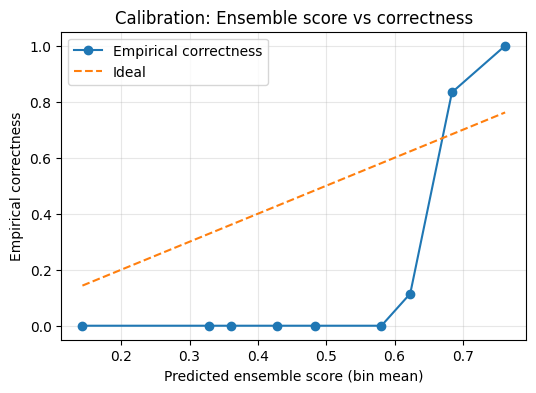

In [ ]:
import matplotlib.pyplot as plt

verifier_corr_accum = {}
verifier_corr_count = {}
disagree_counts = {}
total_diag = 0

all_scores_for_cal = []
all_labels_for_cal = []

diag_actual_judged_candidates = 0
diag_actual_step_prompts_est = 0
diag_full_judged_candidates = 0
diag_full_step_prompts_est = 0

for rec in pool_records[140:200]:
    raw, norm, top_idx, meta = score_problem_record_for_b2(
        rec,
        global_stats=global_stats,
        norm_mode="rank",
        use_llm_judge=use_llm_judge,
        top_n_for_judge=2,
        loo_temp=1.0,
        judge_fill=0.0,
        drop_oracle=True,
        return_meta=True,
    )

    diag_actual_judged_candidates += int(meta["num_llm_judged_candidates"])
    diag_actual_step_prompts_est += int(meta["num_step_judge_prompts_est"])
    diag_full_judged_candidates += len(rec["candidates"])
    diag_full_step_prompts_est += sum(len(split_into_steps(c["text"], max_steps=8)) for c in rec["candidates"])

    w, _ = loo_agreement_weights(norm, temperature=1.0, use_abs=True)
    ens_scores = weighted_candidate_scores(norm, w)
    ens_top = int(np.argmax(ens_scores))

    corr_map = pairwise_verifier_correlations(norm)
    for pair, c in corr_map.items():
        verifier_corr_accum[pair] = verifier_corr_accum.get(pair, 0.0) + c
        verifier_corr_count[pair] = verifier_corr_count.get(pair, 0) + 1

    for v_name, v_scores in norm.items():
        v_top = int(np.argmax(v_scores))
        disagree_counts[v_name] = disagree_counts.get(v_name, 0) + int(v_top != ens_top)

    for i, cand in enumerate(rec["candidates"]):
        label = int(extract_candidate_answer(cand["text"]) == rec["true_answer"])
        all_scores_for_cal.append(float(ens_scores[i]))
        all_labels_for_cal.append(label)

    total_diag += 1

avg_pairwise_corr = [
    {
        "verifier_a": a,
        "verifier_b": b,
        "mean_corr": verifier_corr_accum[(a, b)] / max(verifier_corr_count[(a, b)], 1),
    }
    for (a, b) in verifier_corr_accum
]

pairwise_corr_df = pd.DataFrame(avg_pairwise_corr).sort_values("mean_corr", ascending=False)
disagreement_df = pd.DataFrame(
    [
        {"verifier": v, "disagree_rate_vs_ensemble_top": disagree_counts[v] / max(total_diag, 1)}
        for v in sorted(disagree_counts.keys())
    ]
).sort_values("disagree_rate_vs_ensemble_top", ascending=False)

print("Pairwise verifier correlation (top rows):")
display(pairwise_corr_df.head(12))

print("\nVerifier disagreement vs ensemble top choice:")
display(disagreement_df)

print("\nTwo-stage judge-cost summary (diagnostics slice):")
print("  actual judged candidates:", diag_actual_judged_candidates)
print("  full-baseline judged candidates:", diag_full_judged_candidates)
print("  candidate judge speedup (est):", round(diag_full_judged_candidates / max(diag_actual_judged_candidates, 1), 2))
print("  actual step prompts (est):", diag_actual_step_prompts_est)
print("  full-baseline step prompts (est):", diag_full_step_prompts_est)
print("  step prompt speedup (est):", round(diag_full_step_prompts_est / max(diag_actual_step_prompts_est, 1), 2))

score_arr = np.array(all_scores_for_cal, dtype=float)
label_arr = np.array(all_labels_for_cal, dtype=float)

bins = np.linspace(score_arr.min(), score_arr.max() + 1e-8, 11)
bin_ids = np.digitize(score_arr, bins) - 1

bin_x = []
bin_y = []
for b in range(10):
    mask = bin_ids == b
    if np.sum(mask) == 0:
        continue
    bin_x.append(float(np.mean(score_arr[mask])))
    bin_y.append(float(np.mean(label_arr[mask])))

plt.figure(figsize=(6, 4))
plt.plot(bin_x, bin_y, marker="o", label="Empirical correctness")
plt.plot([min(bin_x), max(bin_x)], [min(bin_x), max(bin_x)], linestyle="--", label="Ideal")
plt.xlabel("Predicted ensemble score (bin mean)")
plt.ylabel("Empirical correctness")
plt.title("Calibration: Ensemble score vs correctness")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


### Robustness Check: Deceptive-Wrong Candidates

Create fluent but wrong variants and measure which verifiers get fooled.


In [ ]:
def verifier_scores_for_two(question, true_answer, cand_a, cand_b):
    raw, norm_rank, top_idx, meta = score_candidates_for_b2(
        question=question,
        true_answer=true_answer,
        candidate_texts=[cand_a, cand_b],
        global_stats=global_stats,
        norm_mode="rank",
        use_llm_judge=use_llm_judge,
        top_n_for_judge=1,
        loo_temp=1.0,
        judge_fill=0.0,
        drop_oracle=False,
        return_meta=True,
    )
    return raw, norm_rank, top_idx, meta


def build_guaranteed_wrong_variant(gold_text, true_answer):
    for nudge in [1, 2, 3, 5, -1, -2, -3, -5]:
        cand = make_deceptive_wrong(gold_text, nudge=nudge)
        parsed = extract_candidate_answer(cand)
        if parsed is not None and parsed != true_answer:
            return cand
    return None


fooled = {}
num_cases = 0
skipped_due_to_no_wrong_variant = 0

for rec in pool_records[140:170]:
    correct_candidates = [c for c in rec["candidates"] if extract_candidate_answer(c["text"]) == rec["true_answer"]]
    if not correct_candidates:
        continue

    gold = correct_candidates[0]["text"]
    deceptive = build_guaranteed_wrong_variant(gold, rec["true_answer"])
    if deceptive is None:
        skipped_due_to_no_wrong_variant += 1
        continue

    raw, norm_rank, _, _ = verifier_scores_for_two(rec["question"], rec["true_answer"], gold, deceptive)

    for v, vals in norm_rank.items():
        if v == "exact_match":
            continue
        fooled[v] = fooled.get(v, 0) + int(vals[1] >= vals[0])

    norm = remove_oracle_verifier(norm_rank)
    w, _ = loo_agreement_weights(norm, temperature=1.0, use_abs=True)
    ens = weighted_candidate_scores(norm, w)
    fooled["ensemble_method1"] = fooled.get("ensemble_method1", 0) + int(ens[1] >= ens[0])

    num_cases += 1

robustness_df = pd.DataFrame(
    [
        {"verifier": k, "fooled_rate": fooled[k] / max(num_cases, 1)}
        for k in sorted(fooled.keys())
    ]
).sort_values("fooled_rate", ascending=False)

print("Robustness cases:", num_cases)
print("Skipped cases (no guaranteed wrong variant found):", skipped_due_to_no_wrong_variant)
display(robustness_df)


Robustness cases: 10
Skipped cases (no guaranteed wrong variant found): 20


,verifier,fooled_rate
1,format_conf,1.0
5,step_plausibility,1.0
4,step_consistency,1.0
3,step_coherence,0.1
0,ensemble_method1,0.0
2,numeric_distance,0.0


In [ ]:
gc.collect()
torch.cuda.empty_cache()

## Final Metric Snapshot


In [ ]:
final_report = {
    "mini_b2": mini_b2_stats,
    "prm_lite": prm_lite_metrics,
    "distillation": distill_metrics,
}

final_report


{'mini_b2': {'n': 20,
  'loo_acc': 1.0,
  'ds_acc': 1.0,
  'loo_parse_fail': 0,
  'ds_parse_fail': 0,
  'errors': 0,
  'nan_count': 0,
  'time_total_s': 273.9399735927582,
  'time_per_ex_s': 13.69699867963791,
  'avg_candidates': 4.0},
 'prm_lite': {'step_accuracy': 0.8304696449026346,
  'no_error_vs_has_error_accuracy': 0.6559139784946236,
  'first_error_index_mae': 0.2374429223744292,
  'num_test_candidates': 279},
 'distillation': {'spearman_teacher_vs_student': 0.39427667494993424,
  'teacher_top_accuracy': 1.0,
  'student_top_accuracy': 0.5,
  'teacher_student_top_agreement': 0.3,
  'performance_retained_pct': 50.0,
  'llm_judged_candidates_actual': 0,
  'llm_judged_candidates_full_baseline': 466,
  'step_prompts_est_actual': 0,
  'step_prompts_est_full_baseline': 1480,
  'candidate_judge_speedup_est': 466.0,
  'step_prompt_speedup_est': 1480.0}}

In [ ]:
notebook_end_time = time.time()

total_seconds = notebook_end_time - notebook_start_time
print("Total notebook runtime (seconds):", round(total_seconds, 2))
print("Runtime (mm:ss):", f"{int(total_seconds // 60)}:{int(total_seconds % 60):02d}")


Total notebook runtime (seconds): 401.76
Runtime (mm:ss): 6:41
